In [1]:
import torch
torch.cuda.is_available()

True

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


In [3]:
from dataclasses import dataclass
import pandas as pd
import torch
from typing import Tuple
import importlib
import wiener_improvements as wi
importlib.reload(wi)
import torchvision.transforms as T
import torchvision.transforms.functional as F
import os,glob, random
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from imagecorruptions import corrupt
import torch.nn as nn
import torch.nn.functional as Fn
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights
from sklearn.metrics import roc_auc_score
import time
import matplotlib.pyplot as plt

C:\Users\Niharika.S.Reddy\AppData\Roaming\Python\Python313\site-packages\imagecorruptions\corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [4]:
import cv2
from skimage.restoration import wiener
from skimage.draw import disk

def detect_defocus_blur(image, threshold=100):
    img = np.array(image.convert("RGB"))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    sharpness = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()
    is_blurry = sharpness < threshold
    return is_blurry, sharpness

In [5]:
def apply_wiener_deconvolution(image, radius=3, balance=0.01):

    img = np.array(image.convert("RGB"))
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    L = lab[:, :, 0].astype(np.float32) / 255.0

    size = radius * 2 + 1
    psf = np.zeros((size, size), dtype=np.float32)

    rr, cc = disk((radius, radius), radius, shape=psf.shape)
    psf[rr, cc] = 1.0
    psf /= psf.sum()

    restored = wiener(
        L,
        psf,
        balance=balance,
        clip=True,
        is_real=True
    )

    lab[:, :, 0] = np.uint8(
        np.clip(restored * 255, 0, 255)
    )

    restored_rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return Image.fromarray(restored_rgb)

In [6]:
def selective_defocus_preprocessing(image, threshold=100):

    is_blurry, sharpness = detect_defocus_blur(
        image, threshold
    )

    if is_blurry:
        image = apply_wiener_deconvolution(image)

    return image, is_blurry, sharpness

In [7]:
@dataclass
class Configuration:
    image_size: int = 256
    batch_size_source: int = 16

    resize_size: int = 256
    crop_size: int = 224
    mean: Tuple[float, ...] = (0.485, 0.456, 0.406)
    std: Tuple[float, ...] = (0.229, 0.224, 0.225)
    backbone_name: str = "wide_resnet50_2"
    feature_layers: Tuple[str, ...] = ("layer2","layer3")
    coreset_ratio: float = 0.2
    adaption_ratio: float = 0.20
    adapt_ratio: float = 0.2
    sinkhorn_lr: float = 1e-4
    epochs: int=10
    batch_size: int = 16
    sinkhorn_eps: float = 0.05
    sinkhorn_iters: int = 50
    corruptions: Tuple[str, ...] = ("gaussian_noise",)
    severity: int=5
    seed: int=42
    num_workers: int=0
    root: str = "./data"
    category: str = "bottle"
    embed_dim: int = 1024
    max_adapt_patches: int = 1024
    adapt_batch_size: int =8
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    seed: int = 42
    assignment: str="discrete"
    aug_mode: str = "augment"

CFG = Configuration()

from contextlib import contextmanager

@contextmanager
def cfg_override(CFG, **kw):
    old = {k: getattr(CFG, k) for k in kw}
    for k, v in kw.items():
        setattr(CFG, k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            setattr(CFG, k, v)

### OpenCV transformation for recall improvement

In [8]:

def convert_to_rgb(image):
    return image.convert("RGB")

def resize(image, image_size):
    return F.resize(
        image,
        [image_size, image_size],
        interpolation=T.InterpolationMode.BILINEAR
    )

def center_crop(image, image_size):
    return F.center_crop(image, [image_size, image_size])

def convert_to_tensor(image):
    return F.to_tensor(image)

def minmax_normalize(tensor, eps=1e-8):
    min_val = tensor.min()
    max_val = tensor.max()
    return (tensor - min_val) / (max_val - min_val + eps)

def normalize_with_imagenet(tensor, mean, std):
    return F.normalize(tensor, mean=list(mean), std=list(std))

def base_transform(image, CFG):
    image = convert_to_rgb(image)
    image = resize(image, CFG.resize_size)
    image = center_crop(image, CFG.crop_size)

    tensor = convert_to_tensor(image)
    tensor = minmax_normalize(tensor)
    return normalize_with_imagenet(tensor, CFG.mean, CFG.std)

In [9]:
def mask_transform(mask, CFG):
    mask = F.resize(mask, [CFG.resize_size, CFG.resize_size], interpolation=F.InterpolationMode.NEAREST)
    mask = F.center_crop(mask, [CFG.crop_size, CFG.crop_size])
    mask = F.to_tensor(mask)
    return (mask > 0.5).float()

In [10]:
class SourceDataset(Dataset):
    def __init__(self, CFG, root="./data", category="bottle"):
        self.CFG = CFG
        self.paths = sorted(glob.glob(os.path.join(root, category, "train", "good", "*.*")))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return base_transform(img, self.CFG)

In [11]:
def apply_corruption(pil_img, name, severity, seed=None):
    if seed is not None:
        np.random.seed(seed)
    arr = np.array(pil_img.convert("RGB"))
    out = corrupt(arr, corruption_name=name, severity=severity)
    return Image.fromarray(np.uint8(out))


In [12]:
class TestDataset(Dataset):
    def __init__(self, root, category, CFG, corruption=None, deblur=None):
        self.CFG = CFG
        self.corruption = corruption
        self.deblur = deblur
        test_dir = os.path.join(root, category, "test")
        gt_dir = os.path.join(root, category, "ground_truth")
        self.items = []
        for defect in sorted(os.listdir(test_dir)):
            for p in sorted(glob.glob(os.path.join(test_dir, defect, "*.*"))):
                if defect == "good":
                    self.items.append((p, 0, None))
                else:
                    stem = os.path.splitext(os.path.basename(p))[0]
                    self.items.append((p, 1, os.path.join(gt_dir, defect, stem + "_mask.png")))
        self.labels = [it[1] for it in self.items]

    def __len__(self):
        return len(self.items)

    def load_corrupted(self, idx):
        path = self.items[idx][0]
        img = Image.open(path).convert("RGB")
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption, self.CFG.severity,
                                   seed=self.CFG.seed + idx)
        return img

    def __getitem__(self, idx):
        _, label, mpath = self.items[idx]
        img = self.load_corrupted(idx)
        if self.deblur is not None:
            img = self.deblur(img)
        x = base_transform(img, self.CFG)
        if mpath is not None and os.path.exists(mpath):
            m = mask_transform(Image.open(mpath).convert("L"), self.CFG)
        else:
            m = torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
        return x, label, m

        if self.corruption == "defocus_blur":

            img, is_blurry, sharpness = selective_defocus_preprocessing(
            img,threshold=100
        )

        x = base_transform(img, self.CFG)

        if mpath is not None and os.path.exists(mpath):
            m=mask_transform(Image.open(mpath).convert("L"), self.CFG)

        else:
            m=torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
        return x, label, m

In [13]:
def split_target(dataset, CFG):
    idx = np.arange(len(dataset))
    tr_idx, te_idx = train_test_split(
        idx, train_size=CFG.adapt_ratio, stratify=dataset.labels, random_state=CFG.seed
    )
    return Subset(dataset, tr_idx.tolist()), Subset(dataset, te_idx.tolist())

In [14]:
class AdaptDataset(Dataset):
    def __init__(self, subset, augment=True):
        self.subset = subset
        self.augment = augment

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        x, _, _ = self.subset[idx]
        if self.augment:
            k = random.randint(0, 3)
            x = torch.rot90(x, k, dims=(1, 2))
        return x

In [15]:
def build_loaders(root, category, corruption, CFG):
    source_ds = SourceDataset(CFG, root, category)
    target_ds = TestDataset(root, category, CFG, corruption=corruption)
    target_tr, target_te = split_target(target_ds, CFG)

    source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                               num_workers=CFG.num_workers)
    adapt_loader = DataLoader(AdaptDataset(target_tr), batch_size=CFG.batch_size, shuffle=True,
                              num_workers=CFG.num_workers, drop_last=True)
    test_loader = DataLoader(target_te, batch_size=CFG.batch_size, shuffle=False,
                             num_workers=CFG.num_workers)
    return source_loader, adapt_loader, test_loader

In [16]:
class FeatureExtractor(nn.Module):
    def __init__(self, CFG):
        super().__init__()
        net = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3 = net.layer1, net.layer2, net.layer3
        self.embed_dim = CFG.embed_dim
        for p in self.parameters():
            p.requires_grad = False

    def forward(self, x):
        x = self.layer1(self.stem(x))
        f2 = self.layer2(x)
        f3 = self.layer3(f2)

        f2 = Fn.avg_pool2d(f2, 3, 1, 1)
        f3 = Fn.avg_pool2d(f3, 3, 1, 1)

        f3 = Fn.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
        f = torch.cat([f2, f3], dim=1)

        B, C, H, W = f.shape
        f = f.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
        f = Fn.adaptive_avg_pool1d(f, self.embed_dim).squeeze(1)
        return f.reshape(B, H * W, self.embed_dim)

@torch.no_grad()
def extract_source_features(model, loader, device):
    model.eval()
    all_feats = []
    for x in loader:
        all_feats.append(model(x.to(device)))
    feats = torch.cat(all_feats, dim=0)
    return feats.reshape(-1, feats.shape[-1])

@torch.no_grad()
def greedy_coreset(features, n_select, proj_dim=128, seed=0):
    device = features.device
    g = torch.Generator(device=device).manual_seed(seed)
    proj = torch.randn(features.shape[1], proj_dim, generator=g, device=device)
    reduced = features @ proj
    N = reduced.shape[0]

    selected = torch.empty(n_select, dtype=torch.long, device=device)
    selected[0] = torch.randint(0, N, (1,), generator=g, device=device)
    min_d = torch.cdist(reduced, reduced[selected[0]].unsqueeze(0)).squeeze(1)

    for i in range(1, n_select):
        nxt = torch.argmax(min_d)
        selected[i] = nxt
        d = torch.cdist(reduced, reduced[nxt].unsqueeze(0)).squeeze(1)
        min_d = torch.minimum(min_d, d)
    return features[selected]


def build_memory_bank(model, source_loader, CFG):
    feats = extract_source_features(model, source_loader, CFG.device)
    n_m = int(CFG.coreset_ratio * feats.shape[0])
    print(f"Source patches: {feats.shape[0]}, memory bank size N_M: {n_m}")
    bank = greedy_coreset(feats, n_m)
    del feats
    torch.cuda.empty_cache()
    return bank


@torch.no_grad()
def score_images(model, loader, memory_bank, device):
    model.eval()
    scores, labels = [], []
    for x, y, _ in loader:
        feats = model(x.to(device))
        for i in range(feats.shape[0]):
            d = torch.cdist(feats[i], memory_bank)
            patch_scores = d.min(dim=1).values
            scores.append(patch_scores.max().item())
        labels.extend(y.tolist())
    return np.array(scores), np.array(labels)


model = FeatureExtractor(CFG).to(CFG.device)
source_ds = SourceDataset(CFG, CFG.root, CFG.category)
source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False, num_workers=CFG.num_workers)
memory_bank = build_memory_bank(model, source_loader, CFG)
clean_ds = TestDataset(CFG.root, CFG.category, CFG, corruption=None)
clean_loader = DataLoader(clean_ds, batch_size=CFG.batch_size, shuffle=False,num_workers=CFG.num_workers)
s, y = score_images(model, clean_loader, memory_bank, CFG.device)
print("Clean image AUROC:", roc_auc_score(y, s))

Source patches: 163856, memory bank size N_M: 32771
Clean image AUROC: 1.0


In [17]:
def make_test_split(corruption, CFG, use_wiener=False):
    ds = TestDataset(CFG.root, CFG.category, CFG, corruption=corruption)
    tr, te = split_target(ds, CFG)

    if use_wiener and corruption == "defocus_blur":
        good = sorted(glob.glob(os.path.join(CFG.root, CFG.category, "train", "good", "*.*")))
        ref = wi.reference_sharpness(good)


        imgs = [ds.load_corrupted(i) for i in tr.indices[:20]]
        ds.deblur = wi.DomainDeblur(ref, blur_ratio=0.5, blend=0.7).fit(imgs)
        print(f"{CFG.category}: wiener active={ds.deblur.active}, "
              f"radius={ds.deblur.radius}, balance={ds.deblur.balance}")
    return tr, te

def make_loader(subset, CFG):
    return DataLoader(subset, batch_size=CFG.batch_size, shuffle=False,num_workers=CFG.num_workers)

def evaluate(model, loader, memory_bank, CFG):
    s, y = score_images(model, loader, memory_bank, CFG.device)
    return roc_auc_score(y, s)

baseline_results = {}

_, clean_te = make_test_split(None, CFG)
baseline_results["clean"] = evaluate(model, make_loader(clean_te, CFG), memory_bank, CFG)
print(f"clean: {baseline_results['clean']:.4f}")


for c in CFG.corruptions:
    _, target_te = make_test_split(c, CFG)
    baseline_results[c] = evaluate(model, make_loader(target_te, CFG), memory_bank, CFG)
    print(f"{c}: {baseline_results[c]:.4f}")

print(pd.Series(baseline_results, name="w/o adapt AUROC").round(4))

clean: 1.0000
gaussian_noise: 0.8248
clean             1.0000
gaussian_noise    0.8248
Name: w/o adapt AUROC, dtype: float64


In [18]:
def cost_matrix(z, bank):
    return torch.cdist(z, bank)

def sample_patches(feats, max_patches):
    z = feats.reshape(-1, feats.shape[-1])
    if z.shape[0] > max_patches:
        idx = torch.randperm(z.shape[0], device=z.device)[:max_patches]
        z = z[idx]
    return z

@torch.no_grad()
def sinkhorn(C, eps, n_iters):
    N, M = C.shape
    Cn = C / C.mean()
    logK = -Cn / eps
    log_a = -torch.log(torch.tensor(float(N), device=C.device))
    log_b = -torch.log(torch.tensor(float(M), device=C.device))
    log_u = torch.zeros(N, device=C.device)
    log_v = torch.zeros(M, device=C.device)
    for _ in range(n_iters):
        log_u = log_a - torch.logsumexp(logK + log_v[None, :], dim=1)
        log_v = log_b - torch.logsumexp(logK + log_u[:, None], dim=0)
    return torch.exp(logK + log_u[:, None] + log_v[None, :])


@torch.no_grad()

def discretize(gamma):
    N, M = gamma.shape
    pi = torch.zeros(N, M, dtype=torch.bool, device=gamma.device)
    pi[torch.arange(N, device=gamma.device), gamma.argmax(dim=1)] = True
    pi[gamma.argmax(dim=0), torch.arange(M, device=gamma.device)] = True
    return pi


def robust_sinkhorn_loss(feats, bank, CFG, return_stats=False):
    z = sample_patches(feats, CFG.max_adapt_patches)
    C = cost_matrix(z, bank)
    gamma = sinkhorn(C.detach(), CFG.sinkhorn_eps, CFG.sinkhorn_iters)
    pi = discretize(gamma)
    loss = C[pi].sum() / z.shape[0]
    if return_stats:
        return loss, gamma, pi
    return loss


tr, _ = make_test_split("gaussian_noise", CFG)
batch = next(iter(DataLoader(AdaptDataset(tr), batch_size=CFG.batch_size, shuffle=True)))

with torch.no_grad():
    feats = model(batch.to(CFG.device))
loss, gamma, pi = robust_sinkhorn_loss(feats, memory_bank, CFG, return_stats=True)

N, M = gamma.shape
print("loss:", loss.item())
print("row sums vs 1/N_tp:", gamma.sum(1).mean().item(), 1 / N)
print("col sums vs 1/N_M :", gamma.sum(0).mean().item(), 1 / M)
print("nonzeros in pi:", pi.sum().item(), "of", N * M)

loss: 58.65203857421875
row sums vs 1/N_tp: 0.0009765629656612873 0.0009765625
col sums vs 1/N_M : 3.0514798709191382e-05 3.0514784413048123e-05
nonzeros in pi: 33279 of 33557504


In [19]:
def make_adapt_model(CFG):
    m = FeatureExtractor(CFG).to(CFG.device)
    bn_params = []
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            for p in (mod.weight, mod.bias):
                p.requires_grad = True
                bn_params.append(p)
    m.eval()
    return m, bn_params


def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(AdaptDataset(adapt_subset, augment=True),
                        batch_size=CFG.adapt_batch_size, shuffle=True,
                        num_workers=CFG.num_workers)
    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []
    for epoch in range(CFG.epochs):
        model.eval()
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
        print(f"  epoch {epoch+1}/{CFG.epochs}  loss {history[-1]:.4f}")
    return history


def run_roda(corruption, memory_bank, CFG):
    torch.manual_seed(CFG.seed); random.seed(CFG.seed); np.random.seed(CFG.seed)
    target_tr, target_te = make_test_split(corruption, CFG)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    return auroc, history


auroc, hist = run_roda("gaussian_noise", memory_bank, CFG)
print(f"gaussian_noise  w/o adapt: {baseline_results['gaussian_noise']:.4f}  RoDA: {auroc:.4f}")

  epoch 1/10  loss 57.9935
  epoch 2/10  loss 57.0611
  epoch 3/10  loss 55.8026
  epoch 4/10  loss 55.5664
  epoch 5/10  loss 54.4835
  epoch 6/10  loss 53.5775
  epoch 7/10  loss 52.5291
  epoch 8/10  loss 51.8811
  epoch 9/10  loss 51.0954
  epoch 10/10  loss 50.1614
gaussian_noise  w/o adapt: 0.8248  RoDA: 0.8824


[gaussian_noise] seed 0
  epoch 1/10  loss 58.9679
  epoch 2/10  loss 57.4496
  epoch 3/10  loss 56.2242
  epoch 4/10  loss 55.5567
  epoch 5/10  loss 54.4327
  epoch 6/10  loss 53.4714
  epoch 7/10  loss 52.0185
  epoch 8/10  loss 51.4758
  epoch 9/10  loss 51.3688
  epoch 10/10  loss 50.3600
  -> AUROC 0.8811
[gaussian_noise] seed 1
  epoch 1/10  loss 58.2060
  epoch 2/10  loss 57.1553
  epoch 3/10  loss 56.2141
  epoch 4/10  loss 55.3075
  epoch 5/10  loss 54.5086
  epoch 6/10  loss 53.7354
  epoch 7/10  loss 52.2109
  epoch 8/10  loss 52.0176
  epoch 9/10  loss 50.9488
  epoch 10/10  loss 50.7089
  -> AUROC 0.8848
[gaussian_noise] seed 2
  epoch 1/10  loss 58.1380
  epoch 2/10  loss 57.8069
  epoch 3/10  loss 56.9695
  epoch 4/10  loss 55.8645
  epoch 5/10  loss 54.2667
  epoch 6/10  loss 52.8738
  epoch 7/10  loss 52.2613
  epoch 8/10  loss 51.7966
  epoch 9/10  loss 51.1590
  epoch 10/10  loss 50.2668
  -> AUROC 0.8824
[gaussian_noise] done in 56s

                clean  w/o adap

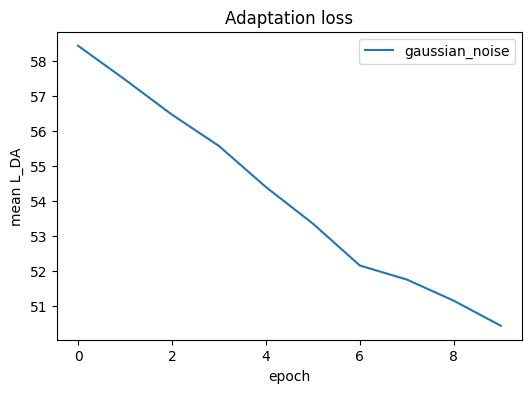

In [20]:
CFG.sinkhorn_lr = 1e-4
CFG.epochs = 10
SEEDS = [0,1,2]

class CachedDataset(Dataset):
    def __init__(self, subset):
        self.items = [subset[i] for i in range(len(subset))]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]


def run_roda_seed(target_tr, target_te, memory_bank, CFG, seed):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    del model_a, bn_params
    torch.cuda.empty_cache()
    return auroc, history

roda_runs = {}
histories = {}


for c in CFG.corruptions:
    t0 = time.time()
    tr, te = make_test_split(c, CFG)
    tr, te = CachedDataset(tr), CachedDataset(te)
    roda_runs[c], histories[c] = [], []
    for sd in SEEDS:
        print(f"[{c}] seed {sd}")
        a, h = run_roda_seed(tr, te, memory_bank, CFG, sd)
        roda_runs[c].append(a)
        histories[c].append(h)
        print(f"  -> AUROC {a:.4f}")
    print(f"[{c}] done in {time.time()-t0:.0f}s\n")


rows = []
for c in CFG.corruptions:
    m, s = np.mean(roda_runs[c]), np.std(roda_runs[c])
    rows.append({
        "corruption": c,
        "clean": baseline_results["clean"],
        "w/o adapt": baseline_results[c],
        "RoDA mean":m,
        "RoDA std":s,
        "diff":m-baseline_results[c],
    })
results_df = pd.DataFrame(rows).set_index("corruption").round(4)
print(results_df)

plt.figure(figsize=(6,4))
for c in CFG.corruptions:
    plt.plot(np.mean(histories[c], axis=0), label=c)
plt.xlabel("epoch")
plt.ylabel("mean L_DA")
plt.legend()
plt.title("Adaptation loss")
plt.show()

[bottle]
Source patches: 163856, memory bank size N_M: 16385
  epoch 1/10  loss 30.0661
  epoch 2/10  loss 29.3029
  epoch 3/10  loss 28.7001
  epoch 4/10  loss 28.3162
  epoch 5/10  loss 27.7540
  epoch 6/10  loss 27.2499
  epoch 7/10  loss 26.5371
  epoch 8/10  loss 26.2377
  epoch 9/10  loss 26.2352
  epoch 10/10  loss 25.6862
  epoch 1/10  loss 29.7035
  epoch 2/10  loss 29.1748
  epoch 3/10  loss 28.6780
  epoch 4/10  loss 28.2252
  epoch 5/10  loss 27.7894
  epoch 6/10  loss 27.3940
  epoch 7/10  loss 26.6391
  epoch 8/10  loss 26.5186
  epoch 9/10  loss 25.9924
  epoch 10/10  loss 25.8812
  epoch 1/10  loss 29.6659
  epoch 2/10  loss 29.4547
  epoch 3/10  loss 29.0648
  epoch 4/10  loss 28.4815
  epoch 5/10  loss 27.6970
  epoch 6/10  loss 26.9679
  epoch 7/10  loss 26.6496
  epoch 8/10  loss 26.4193
  epoch 9/10  loss 26.0986
  epoch 10/10  loss 25.6458
  Gaussian-noise AUROC before RoDA: 0.8566; after RoDA: 0.8889 ± 0.0006
[cable]
Source patches: 175616, memory bank size N_M: 

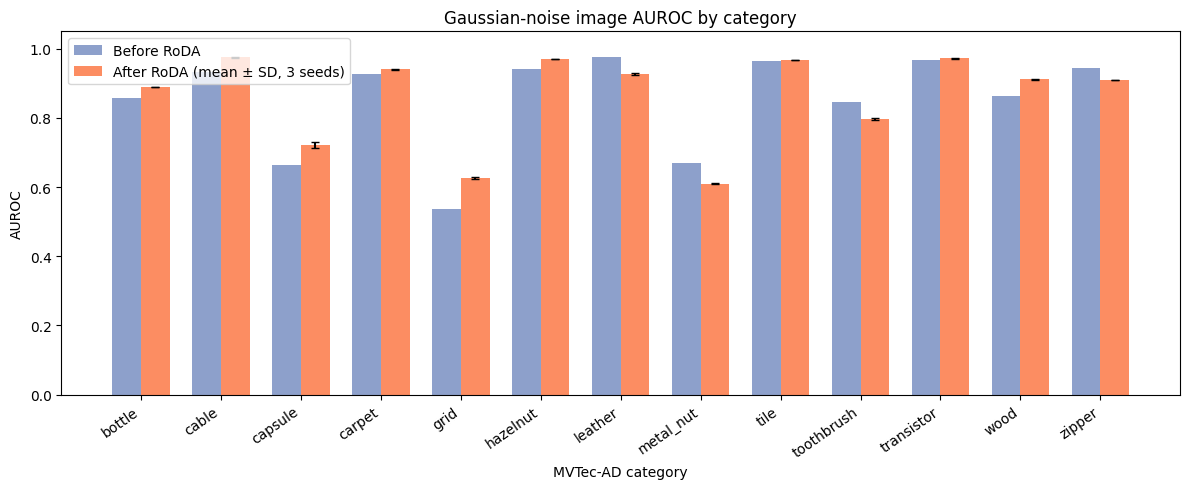

In [21]:
import gc, time
CFG.assignment, CFG.aug_mode = "discrete", "augment"
CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather",
              "metal_nut", "tile", "toothbrush", "transistor", "wood", "zipper"]
CORRUPTION = "gaussian_noise"
SEEDS = [0, 1, 2]
CFG.coreset_ratio = 0.1
base_model = FeatureExtractor(CFG).to(CFG.device)
auroc_rows = []

for cat in CATEGORIES:
    CFG.category = cat
    print(f"[{cat}]")
    src_loader = DataLoader(SourceDataset(CFG, CFG.root, cat), batch_size=CFG.batch_size,
                            shuffle=False, num_workers=CFG.num_workers)
    bank = build_memory_bank(base_model, src_loader, CFG)
    target_tr, target_te = make_test_split(CORRUPTION, CFG)
    target_tr, target_te = CachedDataset(target_tr), CachedDataset(target_te)
    before = evaluate(base_model, make_loader(target_te, CFG), bank, CFG)
    after_runs = [run_roda_seed(target_tr, target_te, bank, CFG, sd)[0] for sd in SEEDS]
    auroc_rows.append({"category": cat, "corruption": CORRUPTION,
                       "before_roda_auroc": before,
                       "after_roda_auroc_mean": float(np.mean(after_runs)),
                       "after_roda_auroc_std": float(np.std(after_runs))})
    print(f"  Gaussian-noise AUROC before RoDA: {before:.4f}; after RoDA: "
          f"{np.mean(after_runs):.4f} ± {np.std(after_runs):.4f}")
    del bank, target_tr, target_te
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

auroc_df = pd.DataFrame(auroc_rows)
plot_df = auroc_df.set_index("category")
x = np.arange(len(plot_df)); width = 0.36
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width/2, plot_df["before_roda_auroc"], width, label="Before RoDA", color="#8da0cb")
ax.bar(x + width/2, plot_df["after_roda_auroc_mean"], width,
       yerr=plot_df["after_roda_auroc_std"], capsize=3,
       label="After RoDA (mean ± SD, 3 seeds)", color="#fc8d62")
ax.set_title("Gaussian-noise image AUROC by category")
ax.set_xlabel("MVTec-AD category"); ax.set_ylabel("AUROC"); ax.set_ylim(0, 1.05)
ax.set_xticks(x, plot_df.index, rotation=35, ha="right")
ax.legend(); fig.tight_layout(); plt.show()
CFG.category = "bottle"


In [22]:
import numpy as np
def get_threshold_at_fpr(normal_scores, target_fpr=0.075):

    normal_scores = np.asarray(normal_scores).reshape(-1)
    threshold = np.quantile(normal_scores, 1.0 - target_fpr)
    return threshold


def compute_recall(scores, labels, threshold):

    scores = np.asarray(scores).reshape(-1)
    labels = np.asarray(labels).reshape(-1)

    preds = (scores >= threshold).astype(int)
    tp = np.sum((preds == 1) & (labels == 1))
    fn = np.sum((preds == 0) & (labels == 1))

    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    return recall, tp, fn


def evaluate_recall(model, test_loader, memory_bank, CFG,
                    normal_loader=None, target_fpr=0.05):

    test_scores, test_labels = score_images(
        model, test_loader, memory_bank, CFG.device
    )

    if normal_loader is not None:
        normal_scores, _ = score_images(
            model, normal_loader, memory_bank, CFG.device
        )
    else:
        normal_scores = test_scores[test_labels == 0]

    threshold = get_threshold_at_fpr(normal_scores, target_fpr)
    recall, tp, fn = compute_recall(test_scores, test_labels, threshold)

    return {
        "recall": recall,
        "threshold": threshold,
        "target_fpr": target_fpr,
        "true_positives": int(tp),
        "false_negatives": int(fn),
        "defective_images": int(tp + fn),
    }

In [23]:
def recall_before_roda(base_model, test_subset, memory_bank, CFG, target_fpr=0.05):
    return evaluate_recall(base_model, make_loader(test_subset, CFG), memory_bank, CFG, normal_loader=None, target_fpr=target_fpr)

def run_roda_seed_with_recall(target_tr, target_te, memory_bank, CFG, seed, target_fpr=0.05):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    res = evaluate_recall(model_a, make_loader(target_te, CFG), memory_bank, CFG,normal_loader=None, target_fpr=target_fpr)
    del model_a, bn_params
    torch.cuda.empty_cache()
    return res, history

Source patches: 172480, memory bank size N_M: 17248
metal_nut    | Gaussian noise | before 0.4730 | after 0.1441 ± 0.0230
Source patches: 171696, memory bank size N_M: 17169
capsule      | Gaussian noise | before 0.4205 | after 0.3826 ± 0.0268
Source patches: 47040, memory bank size N_M: 4704
toothbrush   | Gaussian noise | before 0.5417 | after 0.5000 ± 0.0000
Source patches: 166992, memory bank size N_M: 16699
transistor   | Gaussian noise | before 0.8750 | after 0.8958 ± 0.0390
Source patches: 206976, memory bank size N_M: 20697
grid         | Gaussian noise | before 0.2391 | after 0.3478 ± 0.0000
Saved Gaussian-noise recall tables to Wiener_gaussian_noise_recall.xlsx


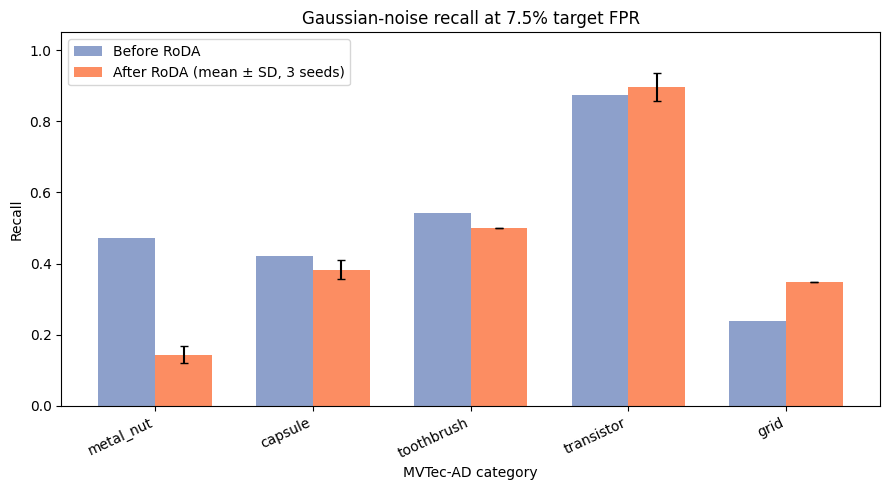

In [24]:
import io
from contextlib import redirect_stdout
CATEGORIES = ["metal_nut", "capsule", "toothbrush", "transistor", "grid"]
CORRUPTION = "gaussian_noise"
SEEDS = [0, 1, 2]
TARGET_FPR = 0.075
RECALL_XLSX = "Wiener_recall.xlsx"
recall_rows = []
base_model = FeatureExtractor(CFG).to(CFG.device)

for category in CATEGORIES:
    with cfg_override(CFG, category=category, coreset_ratio=0.1):
        src = DataLoader(SourceDataset(CFG, CFG.root, category), batch_size=CFG.batch_size,
                         shuffle=False, num_workers=CFG.num_workers)
        bank = build_memory_bank(base_model, src, CFG)
        tr, te = make_test_split(CORRUPTION, CFG)
        tr, te = CachedDataset(tr), CachedDataset(te)
        before = recall_before_roda(base_model, te, bank, CFG, TARGET_FPR)
        after_runs = []
        for seed in SEEDS:
            with redirect_stdout(io.StringIO()):
                result, _ = run_roda_seed_with_recall(tr, te, bank, CFG, seed, TARGET_FPR)
            after_runs.append(result["recall"])
        recall_rows.append({"category": category, "corruption": CORRUPTION,
                            "target_fpr": TARGET_FPR,
                            "before_roda_recall": before["recall"],
                            "after_roda_recall_mean": float(np.mean(after_runs)),
                            "after_roda_recall_std": float(np.std(after_runs)),
                            "recall_change": float(np.mean(after_runs) - before["recall"]),
                            "seeds": len(SEEDS)})
        print(f"{category:12s} | Gaussian noise | before {before['recall']:.4f} | "
              f"after {np.mean(after_runs):.4f} ± {np.std(after_runs):.4f}")
        del bank, tr, te
        if torch.cuda.is_available(): torch.cuda.empty_cache()

recall_df = pd.DataFrame(recall_rows)
recall_summary = pd.DataFrame([{
    "corruption": CORRUPTION, "target_fpr": TARGET_FPR,
    "before_roda_recall_mean": recall_df["before_roda_recall"].mean(),
    "after_roda_recall_mean": recall_df["after_roda_recall_mean"].mean(),
    "after_roda_recall_std_across_categories": recall_df["after_roda_recall_mean"].std(),
    "mean_recall_change": recall_df["recall_change"].mean(),
    "category_count": len(recall_df)}])
with pd.ExcelWriter(RECALL_XLSX, engine="openpyxl") as writer:
    recall_df.to_excel(writer, sheet_name="Gaussian Recall", index=False)
    recall_summary.to_excel(writer, sheet_name="Summary", index=False)
print(f"Saved Gaussian-noise recall tables to {RECALL_XLSX}")

plot_df = recall_df.set_index("category")
x = np.arange(len(plot_df)); width = 0.36
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, plot_df["before_roda_recall"], width, label="Before RoDA", color="#8da0cb")
ax.bar(x + width/2, plot_df["after_roda_recall_mean"], width,
       yerr=plot_df["after_roda_recall_std"], capsize=3,
       label="After RoDA (mean ± SD, 3 seeds)", color="#fc8d62")
ax.set_title("Gaussian-noise recall at 7.5% target FPR")
ax.set_xlabel("MVTec-AD category"); ax.set_ylabel("Recall"); ax.set_ylim(0, 1.05)
ax.set_xticks(x, plot_df.index, rotation=25, ha="right")
ax.legend(); fig.tight_layout(); plt.show()
